POPULATION (N = 10000)
Population mean (mu) = 64.96
Population SD (sigma) = 12.02

SAMPLE (n = 50)
Sample mean (x-bar) = 65.70
Sample SD (s) = 12.67
Sampling error (x-bar - mu) = 0.74

Means of 5 different random samples of size 50:
Sample 1: mean = 64.14
Sample 2: mean = 65.54
Sample 3: mean = 64.92
Sample 4: mean = 65.02
Sample 5: mean = 64.74


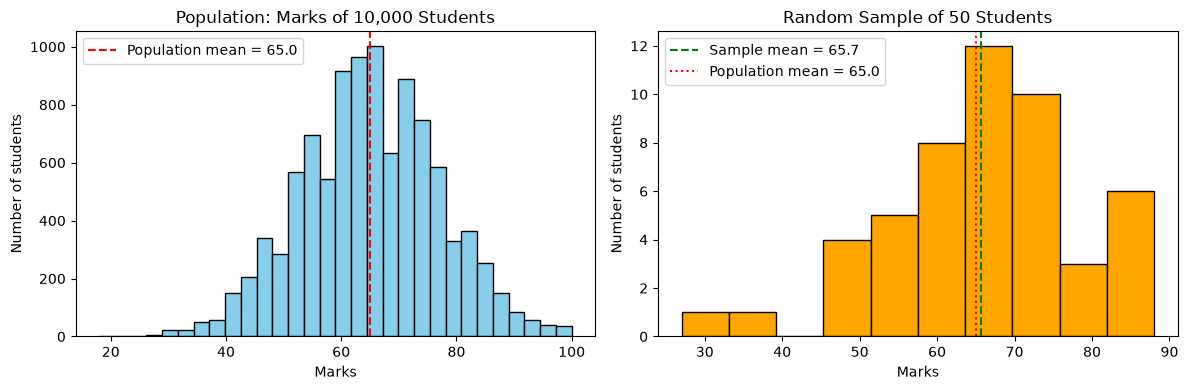

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # to get the same result every time

# Step 1: Create the population - marks of 10,000 students
population = np.random.normal(loc=65, scale=12, size=10000).round()
population = np.clip(population, 0, 100)  # marks must be between 0 and 100

# Step 2: Draw a simple random sample of 50 students (without replacement)
sample = np.random.choice(population, size=50, replace=False)

# Step 3: Compare population parameters and sample statistics
print("POPULATION (N = 10000)")
print(f"Population mean (mu) = {population.mean():.2f}")
print(f"Population SD (sigma) = {population.std():.2f}")
print("\nSAMPLE (n = 50)")
print(f"Sample mean (x-bar) = {sample.mean():.2f}")
print(f"Sample SD (s) = {sample.std(ddof=1):.2f}")
print(f"Sampling error (x-bar - mu) = {sample.mean() - population.mean():.2f}")

# Step 4: Different random samples give different sample means
print("\nMeans of 5 different random samples of size 50:")
for i in range(1, 6):
    s = np.random.choice(population, size=50, replace=False)
    print(f"Sample {i}: mean = {s.mean():.2f}")

# Step 5: Graph
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(population, bins=30, color='skyblue', edgecolor='black')
ax[0].axvline(
    population.mean(),
    color='red',
    linestyle='--',
    label=f'Population mean = {population.mean():.1f}'
)
ax[0].set_title('Population: Marks of 10,000 Students')
ax[0].set_xlabel('Marks')
ax[0].set_ylabel('Number of students')
ax[0].legend()

ax[1].hist(sample, bins=10, color='orange', edgecolor='black')
ax[1].axvline(
    sample.mean(),
    color='green',
    linestyle='--',
    label=f'Sample mean = {sample.mean():.1f}'
)
ax[1].axvline(
    population.mean(),
    color='red',
    linestyle=':',
    label=f'Population mean = {population.mean():.1f}'
)
ax[1].set_title('Random Sample of 50 Students')
ax[1].set_xlabel('Marks')
ax[1].set_ylabel('Number of students')
ax[1].legend()

plt.tight_layout()
plt.show()

Sample size (n) = 36
Sample mean (x-bar) = 496.67 g
Standard error = 1.3333
Z statistic = -2.5000
Critical value = ± 1.96
p-value = 0.0124

Decision: |Z| > 1.96 -> Reject H0
Interpretation: The machine is NOT filling 500 g on average. It needs adjustment.


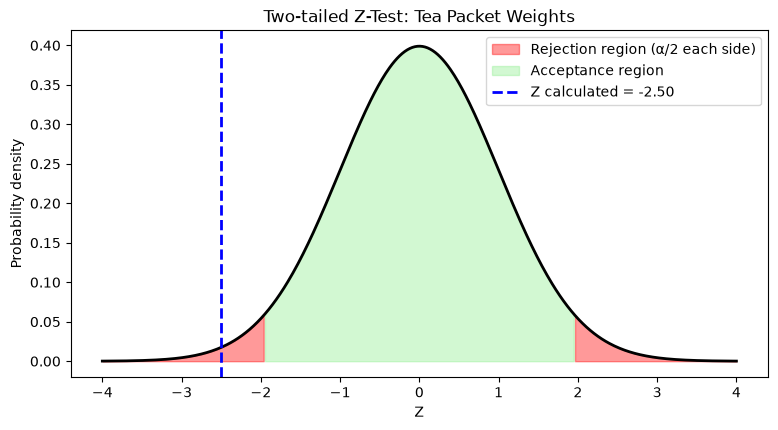

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Step 1: Data - weights (g) of 36 packets
weights = np.array([495, 498, 492, 501, 497, 494, 499, 496, 503, 490, 497, 500, 
                    493, 498, 495, 502, 491, 497, 499, 494, 496, 500, 492, 498, 
                    497, 495, 501, 493, 496, 499, 494, 498, 502, 495, 497, 496])
mu0 = 500       # claimed mean
sigma = 8       # known population SD
alpha = 0.05
n = len(weights)
x_bar = weights.mean()

# Step 2: Z statistic
se = sigma / np.sqrt(n)
z = (x_bar - mu0) / se

# Step 3: Critical value and p-value (two-tailed)
z_critical = stats.norm.ppf(1 - alpha / 2)
p_value = 2 * (1 - stats.norm.cdf(abs(z)))

print(f"Sample size (n) = {n}")
print(f"Sample mean (x-bar) = {x_bar:.2f} g")
print(f"Standard error = {se:.4f}")
print(f"Z statistic = {z:.4f}")
print(f"Critical value = ± {z_critical:.2f}")
print(f"p-value = {p_value:.4f}")

# Step 4: Decision rule
if abs(z) > z_critical:
    print("\nDecision: |Z| > 1.96 -> Reject H0")
    print("Interpretation: The machine is NOT filling 500 g on average. It needs adjustment.")
else:
    print("\nDecision: |Z| <= 1.96 -> Fail to reject H0")
    print("Interpretation: The machine is filling 500 g on average.")

# Step 5: Graph - standard normal curve with rejection regions
x = np.linspace(-4, 4, 500)
y = stats.norm.pdf(x)
plt.figure(figsize=(9, 4.5))
plt.plot(x, y, 'k', lw=2)
plt.fill_between(x, y, where=(x <= -z_critical), color='red', alpha=0.4, label='Rejection region (α/2 each side)')
plt.fill_between(x, y, where=(x >= z_critical), color='red', alpha=0.4)
plt.fill_between(x, y, where=(abs(x) < z_critical), color='lightgreen', alpha=0.4, label='Acceptance region')
plt.axvline(z, color='blue', linestyle='--', lw=2, label=f'Z calculated = {z:.2f}')
plt.title('Two-tailed Z-Test: Tea Packet Weights')
plt.xlabel('Z')
plt.ylabel('Probability density')
plt.legend()
plt.show()